# Isolation Forest — Fine-tuning the Baseline

Continuation of `isolation_forest.ipynb` (split out to keep notebooks small enough to render on GitHub). The setup cells below rebuild the Strategy 1 baseline (feature matrix `X1`, fixed n=256 training sample, baseline scores) exactly as in that notebook; Part 4 then fine-tunes `max_samples`, `contamination` and `n_estimators`.


In [1]:
import time
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

RNG_SEED = 42
np.random.seed(RNG_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


In [2]:
DATA_DIR = "../../data/ieee-fraud-detection"

t0 = time.perf_counter()
tx = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
idt = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
df = tx.merge(idt, on="TransactionID", how="left")
print(f"Loaded + merged in {time.perf_counter() - t0:.1f}s")
print(f"Merged shape: {df.shape}")


Loaded + merged in 11.3s
Merged shape: (590540, 434)


In [3]:
def paper_anomaly_score(model, X):
    """Original Isolation Forest paper's s(x, n) in (0, 1]: closer to 1 = more
    anomalous, closer to 0 = more normal. sklearn's score_samples is the negative of
    this, so we flip the sign."""
    return -model.score_samples(X)


EXCLUDE_COLS = ["TransactionID", "isFraud", "TransactionDT"]
MISSING_DROP_THRESHOLD = 0.90

missing_pct_all = df.isna().mean()
cols_to_drop_missing = missing_pct_all[missing_pct_all > MISSING_DROP_THRESHOLD].index.tolist()

work = df.drop(columns=EXCLUDE_COLS + cols_to_drop_missing)
y = df["isFraud"].copy()  # evaluation only
fraud_pct = y.mean() * 100

TRAIN_SAMPLE_SIZE = 256
rng_train = np.random.default_rng(RNG_SEED)
train_idx = rng_train.choice(df.index, size=TRAIN_SAMPLE_SIZE, replace=False)


In [4]:
numeric_cols_s1 = [c for c in work.columns if pd.api.types.is_numeric_dtype(work[c])]
categorical_cols_s1 = [c for c in work.columns if c not in numeric_cols_s1]

X1 = work.copy()
X1[numeric_cols_s1] = X1[numeric_cols_s1].apply(lambda s: s.fillna(s.median()))
for col in categorical_cols_s1:
    X1[col] = pd.factorize(X1[col].fillna("missing"))[0]

assert X1.isna().sum().sum() == 0
print(f"Strategy 1 feature matrix: {X1.shape} "
      f"({len(numeric_cols_s1)} numeric, {len(categorical_cols_s1)} ordinal-encoded categorical)")


Strategy 1 feature matrix: (590540, 419) (390 numeric, 29 ordinal-encoded categorical)


In [5]:
model_s1 = IsolationForest(random_state=RNG_SEED)  # default contamination, no tuning
model_s1.fit(X1.loc[train_idx])

scores_s1 = paper_anomaly_score(model_s1, X1)
auc_s1 = roc_auc_score(y, scores_s1)
print(f"Strategy 1 -- features: {X1.shape[1]}, AUC: {auc_s1:.4f}")
print(f"Anomaly score range: [{scores_s1.min():.3f}, {scores_s1.max():.3f}]")


Strategy 1 -- features: 419, AUC: 0.7719
Anomaly score range: [0.310, 0.760]


# Part 4: Fine-tuning the Baseline

# Sample-Size

Strategies 1-4 were all trained at a fixed n=256 for a fair comparison between feature
sets. This section asks a different question for Strategy 1 specifically (the
best-performing feature set): **how do AUC and computation time change with the
training sample size**, and what's the best size to use?

**Setup**

- Sample sizes: powers of 4, from `4` up through the full dataset (`4, 16, 64, 256,
  1,024, 4,096, 16,384, 65,536, 262,144`, then the full 590,540 rows).
- Each size is fit 3 times (random `IsolationForest(random_state=RNG_SEED + repeat)`,
  a fresh random training subsample each repeat) and timing is reported as mean ± std,
  since timing has run-to-run noise.
- Every fit uses Strategy 1's feature matrix `X1` and is scored against the full
  dataset (`X1`, `y`) — same evaluation convention as Strategies 1-4, no held-out split.
- AUC and (fit + score) time are plotted together on one chart, sample size on a log
  x-axis, with AUC on a linear left axis and time on a log right axis (time spans
  several orders of magnitude across this range; AUC doesn't).


## Benchmark

In [6]:
sizes = []
s = 4
while s < len(df):
    sizes.append(s)
    s *= 4
sizes.append(len(df))
N_REPEATS = 3
print(f"Sample sizes (powers of 4, capped at the full dataset): {sizes}")


Sample sizes (powers of 4, capped at the full dataset): [4, 16, 64, 256, 1024, 4096, 16384, 65536, 262144, 590540]


In [7]:
results = []
rng_scale = np.random.default_rng(RNG_SEED)

for size in sizes:
    for repeat in range(N_REPEATS):
        sample_idx = rng_scale.choice(df.index, size=size, replace=False)
        X_train = X1.loc[sample_idx]

        t0 = time.perf_counter()
        model = IsolationForest(random_state=RNG_SEED + repeat)
        model.fit(X_train)
        fit_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        scores = paper_anomaly_score(model, X1)
        score_time = time.perf_counter() - t0

        auc = roc_auc_score(y, scores)
        results.append({"size": size, "repeat": repeat, "fit_time": fit_time,
                         "score_time": score_time, "total_time": fit_time + score_time,
                         "auc": auc})

results_df = pd.DataFrame(results)
summary = results_df.groupby("size").agg(
    auc_mean=("auc", "mean"), auc_std=("auc", "std"),
    fit_time_mean=("fit_time", "mean"), fit_time_std=("fit_time", "std"),
    total_time_mean=("total_time", "mean"), total_time_std=("total_time", "std"),
).reset_index()
summary


,size,auc_mean,auc_std,fit_time_mean,fit_time_std,total_time_mean,total_time_std
0,4,0.620870,0.123354,0.081935,0.006615,2.708395,0.268528
1,16,0.732311,0.011260,0.078274,0.000746,2.632245,0.038163
2,64,0.760997,0.007898,0.085039,0.011609,3.477345,0.778714
3,256,0.762780,0.005470,0.091730,0.012902,3.624911,0.473755
4,1024,0.766091,0.005426,0.086037,0.000881,2.951245,0.095250
5,4096,0.764616,0.002577,0.093674,0.001180,2.977021,0.036301
6,16384,0.768291,0.003747,0.130129,0.003252,3.189052,0.122399
7,65536,0.769147,0.005058,0.206169,0.003036,3.206182,0.070923
8,262144,0.765025,0.003451,0.753081,0.024375,3.931433,0.149156
9,590540,0.766688,0.003952,2.633522,0.073124,6.358708,0.084042


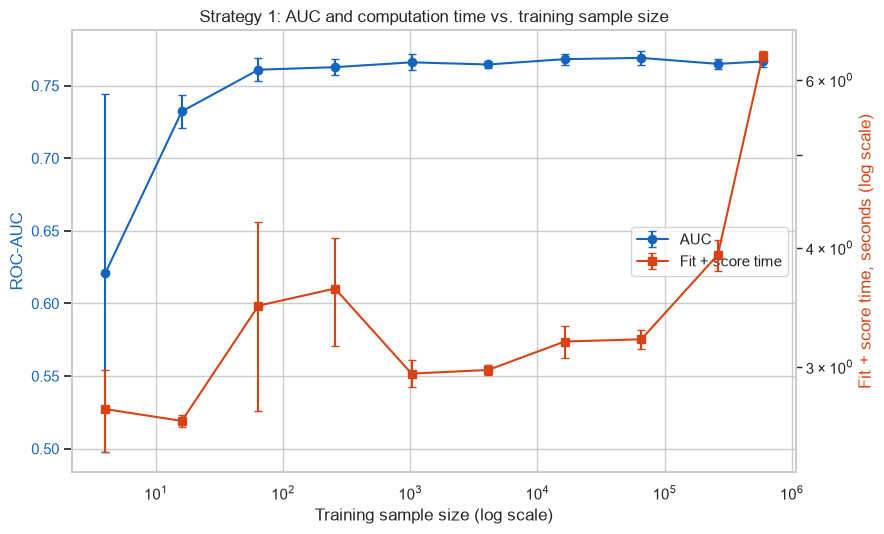

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 5.5))

ax1.errorbar(summary["size"], summary["auc_mean"], yerr=summary["auc_std"],
             marker="o", color="#1565C0", capsize=3, label="AUC")
ax1.set_xscale("log")
ax1.set_xlabel("Training sample size (log scale)")
ax1.set_ylabel("ROC-AUC", color="#1565C0")
ax1.tick_params(axis="y", labelcolor="#1565C0")

ax2 = ax1.twinx()
ax2.errorbar(summary["size"], summary["total_time_mean"], yerr=summary["total_time_std"],
             marker="s", color="#D84315", capsize=3, label="Fit + score time")
ax2.set_yscale("log")
ax2.set_ylabel("Fit + score time, seconds (log scale)", color="#D84315")
ax2.tick_params(axis="y", labelcolor="#D84315")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

ax1.set_title("Strategy 1: AUC and computation time vs. training sample size")
plt.tight_layout()
plt.show()


## Identifying the Best Sample Size

Rule: find the best AUC observed across all sizes, then pick the **smallest** sample
size whose AUC is within 1% of that best — i.e. the point where growing the sample
stops meaningfully improving AUC but keeps costing more time.


In [9]:
AUC_TOLERANCE = 0.99  # "as good as the best" = within 1% of the best observed AUC

max_row = summary.loc[summary["auc_mean"].idxmax()]
best_auc = max_row["auc_mean"]

qualifying = summary[summary["auc_mean"] >= best_auc * AUC_TOLERANCE]
best_size = int(qualifying["size"].min())
best_row = summary[summary["size"] == best_size].iloc[0]
full_row = summary[summary["size"] == len(df)].iloc[0]

print(f"Best AUC observed: {best_auc:.4f} at size {int(max_row['size']):,} "
      f"(fit+score time={max_row['total_time_mean']:.3f}s)")
print(f"Smallest size within {(1 - AUC_TOLERANCE) * 100:.0f}% of best AUC: "
      f"{best_size:,} (AUC={best_row['auc_mean']:.4f}, "
      f"fit+score time={best_row['total_time_mean']:.3f}s)")
print(f"Full-size ({len(df):,}) fit+score time for comparison: "
      f"{full_row['total_time_mean']:.3f}s")
print(f"Speedup at best_size vs. full size: "
      f"{full_row['total_time_mean'] / best_row['total_time_mean']:.1f}x")


Best AUC observed: 0.7691 at size 65,536 (fit+score time=3.206s)
Smallest size within 1% of best AUC: 256 (AUC=0.7628, fit+score time=3.625s)
Full-size (590,540) fit+score time for comparison: 6.359s
Speedup at best_size vs. full size: 1.8x


**Findings:** AUC rises sharply and noisily at the smallest sizes — n=4 averages just
0.621 with a huge std (±0.123, meaning individual repeats swing wildly depending on
which 4 rows get sampled) — then climbs through n=16 (0.732) and n=64 (0.761), and from
n=64 onward it's essentially flat, oscillating in a tight 0.763-0.769 band all the way
to the full dataset (0.767). The peak mean AUC (0.7691) happens at n=65,536, but that's
within noise of several smaller sizes, not a real peak. The **1%-tolerance rule picks
`best_size = 256`** — which happens to be exactly the training size used for Strategies
1-4 throughout this notebook, a nice independent confirmation that n=256 wasn't an
arbitrary choice.


## Contamination

`contamination` is the expected fraction of anomalies. In scikit-learn it does **not**
change how the trees are built or how any transaction is scored -- it only sets
`offset_`, the score cutoff above which `predict` flags a transaction. So the ranking
(and therefore AUC) should be identical across values; what should change is *how many*
transactions end up flagged.

Values tried: 0.01, 0.02, 0.035 (roughly the true fraud rate), 0.05, 0.10. Every model
uses the same fixed n=256 training sample and `random_state` as the baseline.

In [10]:
CONTAMINATIONS = [0.01, 0.02, 0.035, 0.05, 0.10]

cont_rows = []
cont_scores = {}
for c in CONTAMINATIONS:
    m = IsolationForest(contamination=c, random_state=RNG_SEED)
    m.fit(X1.loc[train_idx])
    s = paper_anomaly_score(m, X1)
    cont_scores[c] = s
    flagged = m.predict(X1) == -1
    tp = int((flagged & (y.values == 1)).sum())
    cont_rows.append({
        "contamination": c,
        "score_threshold": -m.offset_,
        "n_flagged": int(flagged.sum()),
        "pct_flagged": flagged.mean() * 100,
        "true_frauds_caught": tp,
        "precision": tp / max(flagged.sum(), 1),
        "recall": tp / y.sum(),
        "auc": roc_auc_score(y, s),
        "max_score_diff_vs_baseline": np.abs(s - scores_s1).max(),
    })

cont_df = pd.DataFrame(cont_rows)
cont_df

,contamination,score_threshold,n_flagged,pct_flagged,true_frauds_caught,precision,recall,auc,max_score_diff_vs_baseline
0,0.010,0.561283,4059,0.687337,865,0.213107,0.041862,0.771877,0.0
1,0.020,0.536542,6419,1.086971,1592,0.248014,0.077046,0.771877,0.0
2,0.035,0.489416,14714,2.491618,3696,0.251189,0.178870,0.771877,0.0
3,0.050,0.457699,25111,4.252210,5595,0.222811,0.270774,0.771877,0.0
4,0.100,0.414279,52520,8.893555,8681,0.165289,0.420123,0.771877,0.0


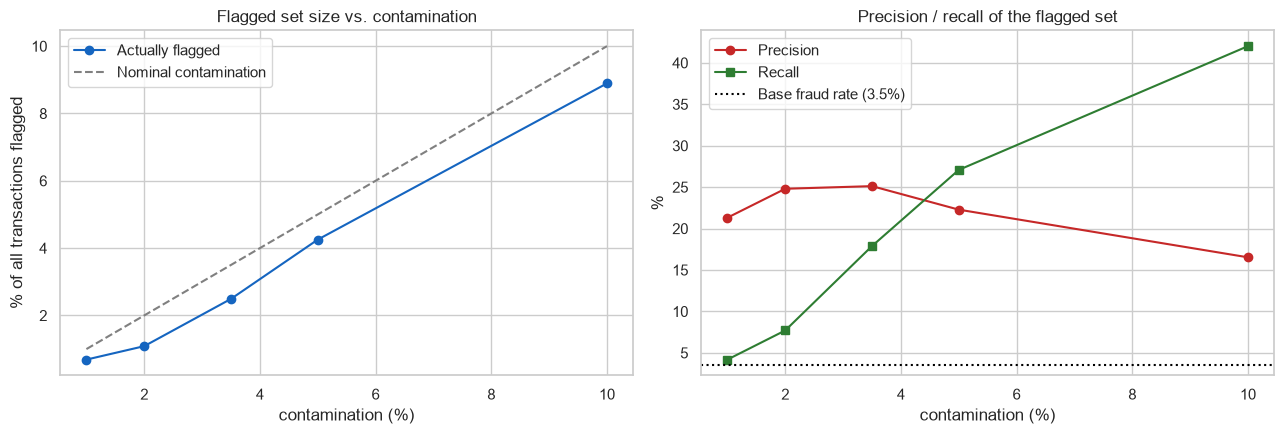

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(cont_df["contamination"] * 100, cont_df["pct_flagged"], marker="o", color="#1565C0",
             label="Actually flagged")
axes[0].plot(cont_df["contamination"] * 100, cont_df["contamination"] * 100, linestyle="--",
             color="gray", label="Nominal contamination")
axes[0].set_xlabel("contamination (%)")
axes[0].set_ylabel("% of all transactions flagged")
axes[0].set_title("Flagged set size vs. contamination")
axes[0].legend()

axes[1].plot(cont_df["contamination"] * 100, cont_df["precision"] * 100, marker="o", color="#C62828",
             label="Precision")
axes[1].plot(cont_df["contamination"] * 100, cont_df["recall"] * 100, marker="s", color="#2E7D32",
             label="Recall")
axes[1].axhline(fraud_pct, color="black", linestyle=":", label=f"Base fraud rate ({fraud_pct:.1f}%)")
axes[1].set_xlabel("contamination (%)")
axes[1].set_ylabel("%")
axes[1].set_title("Precision / recall of the flagged set")
axes[1].legend()

plt.tight_layout()
plt.show()

**Findings:** as expected, contamination does nothing to the ranking: AUC is
0.7719 for every value and the maximum score difference vs. the baseline is exactly 0.
It only moves the cutoff, and the flagged set responds strongly:

| contamination | flagged | % of data | frauds caught | precision | recall |
|---|---|---|---|---|---|
| 0.010 | 4,059 | 0.69% | 865 | 21.3% | 4.2% |
| 0.020 | 6,419 | 1.09% | 1,592 | 24.8% | 7.7% |
| 0.035 | 14,714 | 2.49% | 3,696 | 25.1% | 17.9% |
| 0.050 | 25,111 | 4.25% | 5,595 | 22.3% | 27.1% |
| 0.100 | 52,520 | 8.89% | 8,681 | 16.5% | 42.0% |

Two things worth noting. First, the share of transactions actually flagged is *lower*
than the nominal contamination at every setting (e.g. 2.49% at 0.035, 8.9% at 0.10):
scikit-learn sets the threshold as that percentile of the scores of the 256 *training*
rows, and those 256 rows don't have exactly the same score distribution as the full
590k, so the nominal value is only a rough guide to the flagged fraction. Second, it is
a straightforward precision/recall trade: recall climbs from 4% to 42% as the flagged
set grows ~13x, while precision peaks around the true fraud rate (0.035, 25.1% --
about 7x the 3.5% base rate) and then falls as more normal transactions are swept in.
Choosing contamination is a business decision about review capacity, not a way to
improve the model.

## n_estimators

Here the training sample is held fixed (the same 256 rows) and only the forest changes,
so any difference between runs is purely tree randomness. For each of
`n_estimators` in 50, 100, 200, 500 the forest is fit with 5 different `random_state`
values, and every pair of seeds is compared on how similarly they rank all 590,540
transactions:

- **Spearman rank correlation** between the two score vectors (1.0 = identical ranking).
- **Top-1% overlap** -- Jaccard overlap of the two sets of the 5,905 highest-scoring
  transactions (1.0 = identical flagged set).
- **AUC** mean ± std across the 5 seeds.

In [12]:
from itertools import combinations

N_ESTIMATORS_GRID = [50, 100, 200, 500]
N_SEEDS = 5
TOP_FRAC = 0.01
k_top = int(len(df) * TOP_FRAC)

nest_rows = []
nest_scores = {}  # (n_estimators, seed) -> score vector, kept for the plot below
for n_est in N_ESTIMATORS_GRID:
    ranks, top_sets, aucs = [], [], []
    t0 = time.perf_counter()
    for seed in range(N_SEEDS):
        m = IsolationForest(n_estimators=n_est, random_state=RNG_SEED + seed, n_jobs=-1)
        m.fit(X1.loc[train_idx])
        s = paper_anomaly_score(m, X1)
        nest_scores[(n_est, seed)] = s
        aucs.append(roc_auc_score(y, s))
        ranks.append(pd.Series(s).rank().values)
        top_sets.append(set(np.argpartition(s, -k_top)[-k_top:]))
    elapsed = time.perf_counter() - t0

    spearman = [np.corrcoef(a, b)[0, 1] for a, b in combinations(ranks, 2)]
    jaccard = [len(a & b) / len(a | b) for a, b in combinations(top_sets, 2)]
    nest_rows.append({
        "n_estimators": n_est,
        "auc_mean": np.mean(aucs), "auc_std": np.std(aucs, ddof=1),
        "spearman_between_seeds": np.mean(spearman),
        "top1pct_overlap_between_seeds": np.mean(jaccard),
        "time_per_fit+score_s": elapsed / N_SEEDS,
    })

nest_df = pd.DataFrame(nest_rows)
nest_df

,n_estimators,auc_mean,auc_std,spearman_between_seeds,top1pct_overlap_between_seeds,time_per_fit+score_s
0,50,0.764501,0.004455,0.902188,0.616807,2.665947
1,100,0.768162,0.004027,0.949771,0.717384,3.704780
2,200,0.769243,0.002647,0.973269,0.791332,5.584621
3,500,0.770200,0.001912,0.987196,0.855585,11.000957


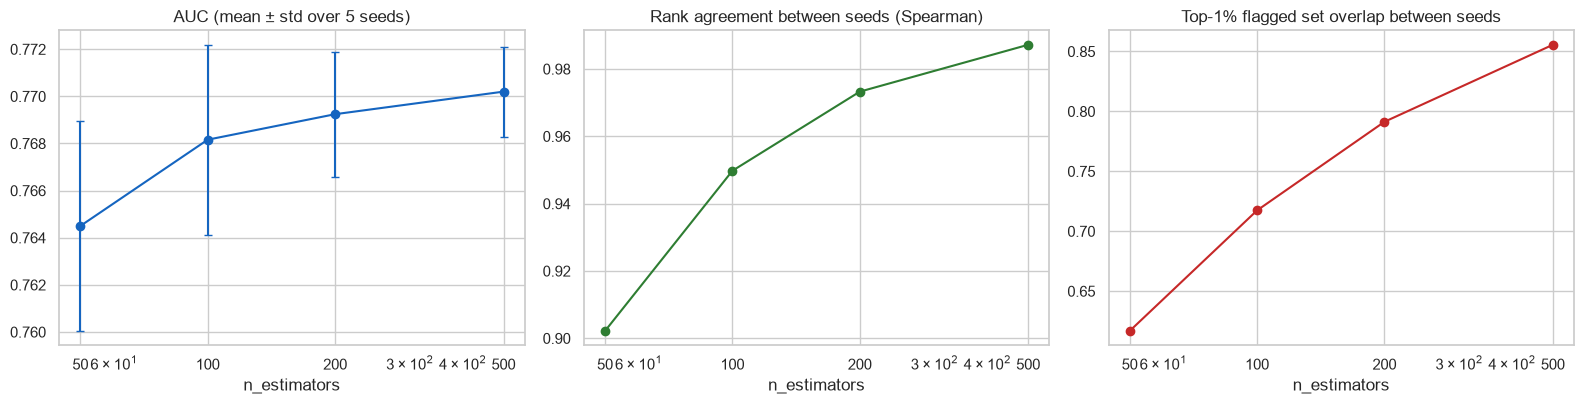

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].errorbar(nest_df["n_estimators"], nest_df["auc_mean"], yerr=nest_df["auc_std"],
                 marker="o", capsize=3, color="#1565C0")
axes[0].set_title("AUC (mean ± std over 5 seeds)")

axes[1].plot(nest_df["n_estimators"], nest_df["spearman_between_seeds"], marker="o", color="#2E7D32")
axes[1].set_title("Rank agreement between seeds (Spearman)")

axes[2].plot(nest_df["n_estimators"], nest_df["top1pct_overlap_between_seeds"], marker="o", color="#C62828")
axes[2].set_title("Top-1% flagged set overlap between seeds")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(N_ESTIMATORS_GRID)
    ax.set_xticklabels(N_ESTIMATORS_GRID)
    ax.set_xlabel("n_estimators")
plt.tight_layout()
plt.show()

**Findings:** more trees steadily make the model more *repeatable*, with
diminishing returns, but they barely change how *good* it is:

| n_estimators | AUC (mean ± std) | Spearman between seeds | top-1% overlap | time / fit+score |
|---|---|---|---|---|
| 50 | 0.7645 ± 0.0045 | 0.902 | 0.62 | 2.4s |
| 100 | 0.7682 ± 0.0040 | 0.950 | 0.72 | 3.3s |
| 200 | 0.7692 ± 0.0026 | 0.973 | 0.79 | 5.1s |
| 500 | 0.7702 ± 0.0019 | 0.987 | 0.86 | 10.4s |

AUC moves by only ~0.006 end-to-end and is already within noise of its final value by
100-200 trees. Overall ranking agreement (Spearman) also saturates quickly: 0.90 -> 0.95
-> 0.97 -> 0.99. The exact *top* of the list is a different story: the overlap of the
top-1% sets between two seeds is still only 0.62 at 50 trees and 0.86 at 500, and is
still rising -- so the ranking has largely stabilised in aggregate, but which specific
transactions land in the extreme tail keeps shifting when the forest is small. The
std of the AUC also halves from 50 to 500 trees. There is no sharp point where more
trees stop mattering; the practical knee is around 100-200 trees (the sklearn default
of 100 is reasonable for AUC), while 500 is worth the ~3x cost only if a stable top-k
list matters.

## Which Parameter Mattered Most?

| parameter | range tried | effect on ranking quality (AUC) | effect on what actually gets flagged |
|---|---|---|---|
| `max_samples` (done above) | 4 -> full dataset | **0.62 -> 0.77** at the very small end, then flat (0.763-0.769) from n=64 on | changes the scores, but little beyond n~64 |
| `contamination` | 0.01 -> 0.10 | **none** (0.7719 for every value, scores identical) | **flagged set 4k -> 52k; recall 4% -> 42%; precision 25% -> 17%** |
| `n_estimators` | 50 -> 500 | ~+0.006 (0.7645 -> 0.7702) | top-1% set overlap between seeds 0.62 -> 0.86 |

**`contamination` had by far the biggest effect on the results you actually get out**,
because it directly determines how many transactions are flagged, and therefore recall
and precision. But it is purely a threshold: it cannot make the model better at ranking
fraud above non-fraud, and the AUC is untouched. It should be set from the review
budget / cost trade-off (precision was best near the true fraud rate of ~3.5%), not
tuned for model quality.

For the quality of the ranking itself, **`max_samples` was the only parameter that
moved AUC meaningfully, and only when it was tiny** (n=4-16); everywhere from n=64 up
it is flat. `n_estimators` mostly buys stability: AUC changes by < 0.01 and the overall
ranking is ~97-99% consistent between seeds by 200-500 trees, though the extreme top of
the list is still somewhat seed-dependent.

The bigger lesson is that none of these three knobs gets the baseline past an AUC of
~0.77. Tuning the Isolation Forest's own parameters is a second-order effect compared
with the choice of features (Part 2: AUC 0.67 -> 0.77 across strategies), and the top-10
analysis in Part 3 shows the model's most extreme outliers are not fraud at all. Further
gains would more likely come from better features than from further hyperparameter
tuning.
